In [ ]:
from huggingface_hub import login
login()

In [7]:
from pathlib import Path
import sys

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sentence_transformers import SentenceTransformer

sys.path.insert(0, str(Path.cwd()))

from data import load_data, make_groups
from evaluation import evaluate, split_data

data = load_data("../data/processed/headlines.csv")
data["group"] = make_groups(data)
labels = sorted(data["label"].unique())
train_indices, test_indices = split_data(data)
train = data.iloc[train_indices]
test = data.iloc[test_indices]

train_sentences = train["headline"].tolist()
test_sentences = test["headline"].tolist()
print(f"Training rows: {len(train)}; test rows: {len(test)}")

Training rows: 323; test rows: 132


In [8]:
model = SentenceTransformer("djovak/embedic-large")

X_train = model.encode(
    train_sentences,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True,
)

X_test = model.encode(
    test_sentences,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True,
)

print(f"Embedding shapes: train={X_train.shape}; test={X_test.shape}")

Batches: 100%|██████████| 5/5 [00:01<00:00,  4.57it/s]

Embedding shapes: train=(323, 1024); test=(132, 1024)


In [9]:
classifier = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42,
)
classifier.fit(X_train, train["label"])
predictions = classifier.predict(X_test)
metrics = evaluate(test["label"], predictions, labels)
report = metrics["report"]

transformer_summary = {
    "accuracy": accuracy_score(test["label"], predictions),
    "macro_precision": report["macro avg"]["precision"],
    "macro_recall": report["macro avg"]["recall"],
    "macro_f1": report["macro avg"]["f1-score"],
    "weighted_f1": report["weighted avg"]["f1-score"],
    "test_rows": len(test),
}
print(transformer_summary)
display(
    pd.DataFrame(report).T[
        ["precision", "recall", "f1-score", "support"]
    ].round(3)
)

{'accuracy': 0.8257575757575758, 'macro_precision': 0.6277156177156178, 'macro_recall': 0.7277336747759283, 'macro_f1': 0.6663678109245047, 'weighted_f1': 0.7883122999689585, 'test_rows': 132}


,precision,recall,f1-score,support
nothing,0.909,0.909,0.909,22.000
personality_cult,0.583,1.000,0.737,7.000
vilifying_eu,0.000,0.000,0.000,12.000
vilifying_neighbours,0.800,0.800,0.800,20.000
vilifying_opponents,0.846,0.930,0.886,71.000
accuracy,0.826,0.826,0.826,0.826
macro avg,0.628,0.728,0.666,132.000
weighted avg,0.759,0.826,0.788,132.000


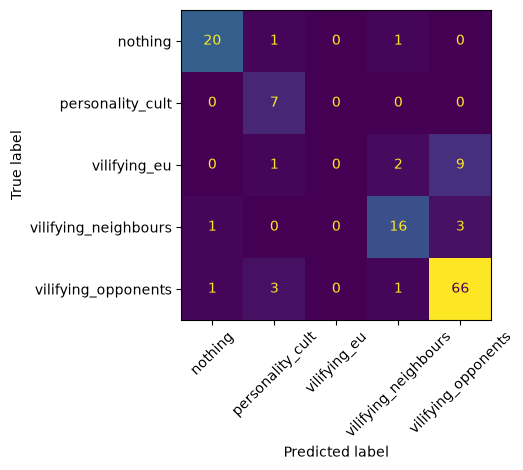

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=metrics["confusion_matrix"],
    display_labels=labels,
).plot(xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.show()